# Representação Semântica de Frases com Embeddings

##### Quatro frases, as duas primeiras falam do mesmo assunto, comer macarrão, e as duas últimas mudam o assunto, falam da bolsa de valores.

### Geração de Embeddings

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from sentence_transformers import SentenceTransformer
from networkx.algorithms.community import greedy_modularity_communities
from sklearn.manifold import TSNE

c:\Users\sofia\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
sentences = [
    "Você já comeu macarrão?",
    "Amo comer macarrão",
    "A bolsa de valores caiu",
    "Sim, eu vi que a bolsa de valores caiu, fiquei preocupado"
]

sentences_e5 = [f"passage: {s}" for s in sentences]
model = SentenceTransformer('intfloat/multilingual-e5-base')

S = model.encode(sentences_e5)

print("\nEmbeddings (S):")
print(S.shape)
print(S)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2591.50it/s]
XLMRobertaModel LOAD REPORT from: intfloat/multilingual-e5-base
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(4, 768)
[[ 0.01124605  0.04026413 -0.01619804 ... -0.02331213 -0.04896245
   0.02372711]
 [-0.01403777  0.04405611 -0.0378157  ... -0.04355169 -0.03896272
   0.03018466]
 [ 0.03197279  0.02794801 -0.0327708  ... -0.0367818  -0.0368611
   0.0111425 ]
 [ 0.02292958  0.0417902  -0.03237897 ... -0.03095924 -0.02972823
   0.01479322]]


### Construção da Matriz de Adjacência

In [3]:
from sklearn.metrics.pairwise import cosine_similarity

scores = cosine_similarity(S)

n = len(sentences)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i: 
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         0.        ]
 [0.90384704 0.         0.         0.        ]
 [0.82840419 0.85202736 0.         0.        ]
 [0.84561288 0.83256787 0.91516829 0.        ]]


### Grafo

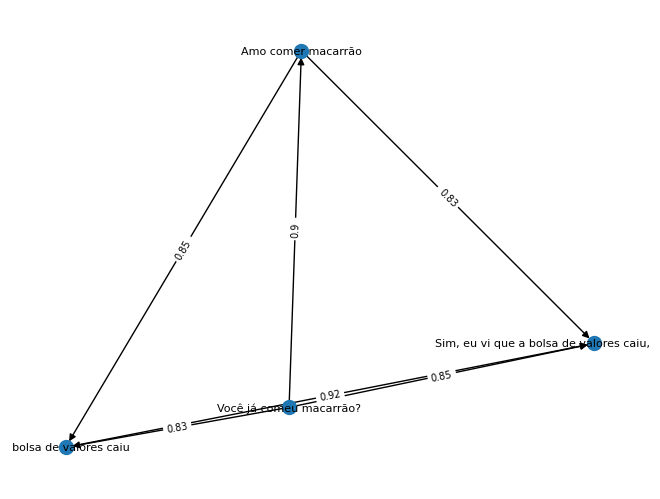

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences_e5):
    G.add_node(i, label=s)

for i in range(n):
    for j in range(n):
        weight = A[i, j]
        if weight > 0.2:
            G.add_edge(j, i, weight=weight)

pos = nx.spring_layout(G)

nx.draw(G, pos, node_size=100)

node_labels = {i: s for i, s in enumerate(sentences)}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8)

edge_labels = {k: round(v, 2) for k, v in nx.get_edge_attributes(G, 'weight').items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)

plt.show()

Você já comeu macarrão? → Cluster 0
Amo comer macarrão → Cluster 0
A bolsa de valores caiu → Cluster 1
Sim, eu vi que a bolsa de valores caiu, fiquei preocupado → Cluster 1


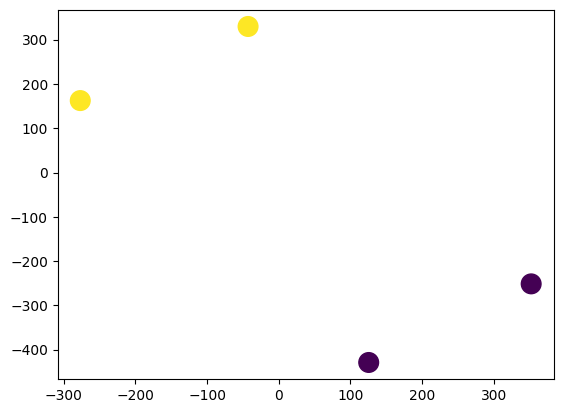

In [5]:
from sklearn.cluster import SpectralClustering

tsne = TSNE(n_components=2, random_state=0, perplexity=2)
S_2d = tsne.fit_transform(S)

similarity = S @ S.T

clustering = SpectralClustering(
    n_clusters=2,
    affinity='precomputed', 
    random_state=0
)

labels = clustering.fit_predict(similarity)

for i, s in enumerate(sentences):
    print(f"{s} → Cluster {labels[i]}")


plt.scatter(S_2d[:,0], S_2d[:,1], c=labels, s=200)